# Session 4 — Classification: Models and Metrics

Session 3 chose between models that predict a **number**. This session moves to models that predict
a **class**: which of several groups a row belongs to. Almost every question a business asks in this
form — will this customer leave, is this transaction fraud, should this application be seen by a
person — is a classification problem.

Two things change when the target becomes a class, and this session is built around them.

**You need models that can answer the question.** Part 1 introduces three, and looks inside each one,
so that you know what it does rather than only what it scores.

**You need a way to say whether an answer is good.** Part 2 shows that the obvious measure — the
share of rows the model gets right — is misleading here, and builds the measures that replace it.

## Learning objectives

By the end of this session you will be able to:

1. Explain how **logistic regression**, a **decision tree** and **k-nearest neighbours** each turn
   features into a predicted class, and draw the decision each one makes on two features.
2. Explain why a classifier's real output is a **probability**, and why different models produce
   probabilities of very different granularity.
3. Show why **accuracy** is misleading when one class is more common than the other.
4. Build a **confusion matrix** and compute **precision**, **recall** and **F1** from it.
5. Treat the **classification threshold** as a business decision rather than a fixed constant, and
   choose it from the cost of each kind of mistake.
6. Read a **ROC curve** and a **precision-recall curve**, and say which one to trust when the
   positive class is rare.
7. Read per-class metrics when there are more than two classes.

## How the session is organized

**Part 1 — Three ways to predict a class.** Each model is introduced on its own terms, then drawn on
one or two measurements from a small dataset of flowers, so that its decision is visible as a picture.

**Part 2 — Measuring a classifier.** Back to a business problem. The same three kinds of model are
fitted on customer data with every feature, and they become the material for every measurement, so
that each metric is read on models you already understand.

> **A note on order.** Part 1 is not a detour. Every measure in Part 2 needs several models to
> compare, and needs you to know why they disagree. Building the models first is what makes the
> second half readable.

The cell below imports everything the notebook uses, and fixes one random seed that every later cell
reuses. Fixing the seed is what makes the numbers quoted in this text reproduce when you run it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.collections import QuadMesh
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42

# Part 1 — Three ways to predict a class

## From predicting a number to predicting a class

In session 3 a model answered with a quantity: this house is worth 184,000. A classifier answers a
question that has a fixed set of possible answers, such as *will this customer leave?* The honest
answer is not "yes". It is **"yes, with probability 0.63"**.

That difference runs through the whole session. A classifier computes a probability, and only then is
that probability turned into a class by comparing it against a **threshold** — a cut-off value above
which we answer "yes". The usual threshold is 0.5, but nothing in the mathematics requires it, and
Part 2 shows it is a business choice.

So each model in this part is really answering the same question in a different way:

> given this row's features, how likely is the answer "yes"?

The three models below reach that number by three completely different routes. **Logistic
regression** computes a weighted sum of the features. **A decision tree** asks a sequence of yes/no
questions. **k-nearest neighbours** looks up the most similar rows and takes a vote. Knowing which route
a model took is what lets you explain its answer to somebody else.

## The Data: iris flowers

We use the **iris** dataset, stored with this repository at `data/iris.csv`.

- **150 rows and 5 columns.**
- **One row is one flower.** Iris is a kind of flowering plant, and every flower here belongs to one of
  three species: *setosa*, *versicolor* or *virginica*. There are 50 flowers of each.
- **Four columns are measurements, in centimetres.** A flower has **petals**, the large coloured
  leaves, and **sepals**, the smaller leaves below them that cover the flower before it opens. Each
  was measured for length and width: `sepal_length`, `sepal_width`, `petal_length`, `petal_width`.
- **The fifth column, `species`, is the class.**
- **Where it comes from.** The botanist Edgar Anderson measured the flowers, and the statistician
  Ronald Fisher published the measurements in 1936, in a paper about telling species apart from
  their measurements. It is still one of the most used datasets for teaching classification.

**Why this dataset serves this part.** Part 1 has to show *how* each model decides, as a picture.
That needs few rows, few features, and features anyone can picture — the size of a leaf. Nothing in
the data needs cleaning, so every cell in this part is about a model.

**One question with two answers.** Until the last section of Part 2, every problem in this session
has two classes. So we ask the iris data one yes/no question: **is this flower a setosa?** The
flowers of the other two species form a single class, called "other".

**No test set in this part.** Part 1 never scores a model. It only draws what each model learned from
all 150 flowers. Part 2 holds a test set back before it fits anything, as session 3 did.

The cell below loads the file, reports its shape and prints five rows:

In [3]:
iris = pd.read_csv("iris.csv")

print(f"{iris.shape[0]} rows x {iris.shape[1]} columns")
iris.head()

150 rows x 5 columns


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


The models need a number as the target. The cell below adds a column that is 1 for a setosa and 0 for
any other flower, so that "this flower is a setosa" is the **positive class** — the answer we are
trying to detect. It then counts the two classes:

In [4]:
iris["is_setosa"] = (iris["species"] == "setosa").astype(int)
y_iris = iris["is_setosa"]

y_iris.value_counts()

is_setosa
0    100
1     50
Name: count, dtype: int64

**50 setosa flowers and 100 others.**

Before drawing a model, we choose which measurements to draw it on, and the data can make that
choice. A model only has something interesting to show where the two classes **overlap**: a range of
values in which both setosa and other flowers occur. Outside that range one value decides the class
on its own.

The cell below draws a **pair plot**: a grid with one scatter plot for every pair of measurements,
coloured by class (orange for setosa, blue for other). The diagonal is different: for each single
measurement it shows a smoothed curve of how the values are spread within each class. Look for
measurements where the two colours do not overlap:

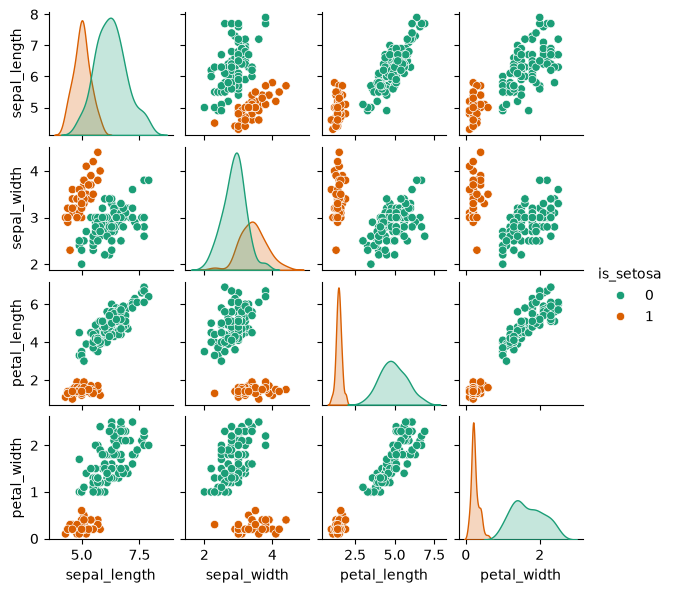

In [10]:
MEASUREMENT_COLS = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = iris[MEASUREMENT_COLS]

sns.pairplot(iris, vars=MEASUREMENT_COLS, hue="is_setosa", height=1.5, palette="Dark2")
plt.show()

**The petal measurements do not overlap at all.** In every panel that uses `petal_length` or
`petal_width`, the orange setosa points form a separate group, and on the diagonal the two curves
never meet. Classes that one cut can divide without a single error are called **perfectly
separable**. Any model gets them right, and there is nothing uncertain left to draw.

**The sepal measurements do overlap.** On the diagonal, the two curves for `sepal_length` share a
range of values, and the two curves for `sepal_width` share even more. Here a model has to decide,
and its probabilities have something to show. So the one-feature picture uses `sepal_length`, the
sepal measurement that overlaps less, and the two-feature pictures use both sepal measurements.

The cell below records that choice in one variable, so that it can be changed in one place:

In [9]:
feature_1d = "sepal_length"

## Logistic regression

Start from what session 3 already gave you. A linear model computes a weighted sum of the features:

$$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

where:

- $z$ — the **score**, a single number. It can be anything from $-\infty$ to $+\infty$.
- $x_1 \dots x_p$ — the feature values for one row.
- $\beta_1 \dots \beta_p$ — one weight per feature, solved for during `fit`. Each says how much that
  feature moves the score.
- $\beta_0$ — the **intercept**, the score when every feature is 0.
- $p$ — the number of features.

That score cannot be a probability, because probabilities must lie between 0 and 1 and $z$ does not.
So we pass it through a function that squashes any number into that range — the **sigmoid**:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

where:

- $\sigma(z)$ — the predicted probability of the positive class, always between 0 and 1.
- $z$ — the score from the line above.
- $e$ — Euler's number, about 2.718.

The shape is the point. When $z = 0$ the sigmoid returns exactly 0.5. Large positive scores flatten
towards 1, large negative scores flatten towards 0, and the curve moves fastest in between.

The cell below draws the sigmoid and prints its value at three scores. Check the value at 0, and how
close the two extreme scores get to 0 and 1:

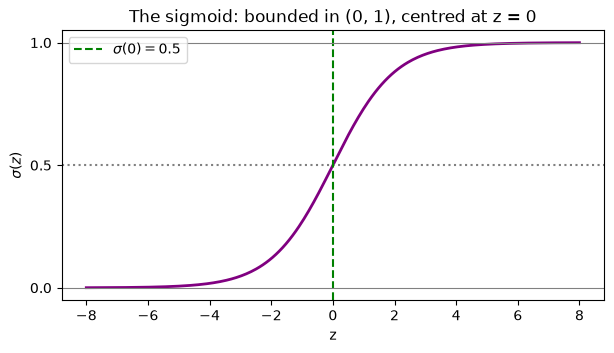

sigma(-100) = 0.0000
sigma(0)    = 0.5000
sigma(100)  = 1.0000


In [7]:
def sigmoid(z: np.ndarray) -> np.ndarray:
    """Map real values into the (0, 1) interval.

    Args:
        z: Input values, any real numbers.

    Returns:
        Values in (0, 1), equal to exactly 0.5 where `z` is 0.
    """
    return 1 / (1 + np.exp(-z))


z_grid = np.linspace(-8, 8, 300)

plt.figure(figsize=(7, 3.5))
plt.plot(z_grid, sigmoid(z_grid), color="purple", linewidth=2)
plt.axhline(0.5, color="gray", linestyle=":")
plt.axvline(0, color="green", linestyle="--", label="$\\sigma(0) = 0.5$")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axhline(1, color="gray", linewidth=0.8)
plt.yticks([0, 0.5, 1])
plt.xlabel("z")
plt.ylabel("$\\sigma(z)$")
plt.title("The sigmoid: bounded in (0, 1), centred at z = 0")
plt.legend()
plt.show()

print(f"sigma(-100) = {sigmoid(np.array(-100.0)):.4f}")
print(f"sigma(0)    = {sigmoid(np.array(0.0)):.4f}")
print(f"sigma(100)  = {sigmoid(np.array(100.0)):.4f}")

So **logistic regression is a linear model wearing a squashing function**: it keeps the weighted sum,
and converts it into something that can be read as a probability.

> **In `scikit-learn`.** `LogisticRegression()` fits it. Despite the name it is a classifier, not a
> regressor.
>
> The method `predict_proba(X)` returns the probabilities in two columns — column 1 is the positive class — while `predict(X)` applies a 0.5 threshold for you and returns classes.

To see the fitted sigmoid we need a picture, and a picture needs one feature. We use `feature_1d`,
the measurement chosen above: sepal length.

The cell below fits logistic regression on sepal length alone and prints its weight and intercept.
It then builds a table with one row per flower: the sepal length, the true class, the predicted
probability of each class, and the class predicted at the 0.5 threshold. `P(y=1|feature)` reads
"the probability that the flower is a setosa, given its sepal length". Five random rows are shown —
check that the two probabilities in each row add up to 1:

In [14]:
sepal_model = LogisticRegression()
sepal_model.fit(iris[[feature_1d]], y_iris)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [15]:
print(f"weight on {feature_1d}: {sepal_model.coef_[0][0]:.4f}")
print(f"intercept: {sepal_model.intercept_[0]:.4f}")

weight on sepal_length: -3.4585
intercept: 18.5496


In [16]:
sepal_model_predictions = pd.DataFrame({
    feature_1d: iris[feature_1d],
    "is_setosa": iris["is_setosa"],
})
sepal_model_predictions.head()

,sepal_length,is_setosa
0,5.1,1
1,4.9,1
2,4.7,1
3,4.6,1
4,5.0,1


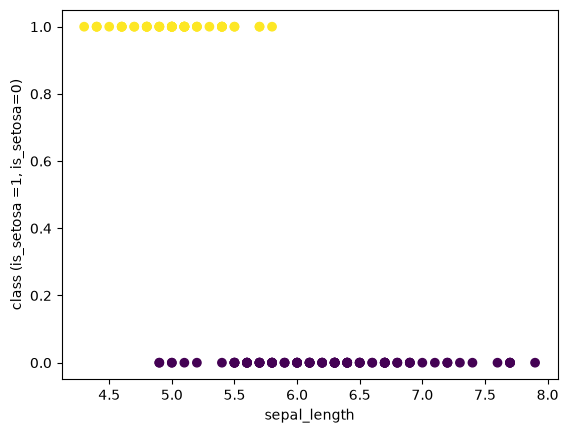

In [19]:
fig=plt.Figure(figsize=(4, 3))
plt.scatter(
    x=sepal_model_predictions.sepal_length,
    y=sepal_model_predictions.is_setosa,
    c=sepal_model_predictions.is_setosa
    )

plt.xlabel("sepal_length")
plt.ylabel("class (is_setosa =1, is_setosa=0)")
plt.show()

In [21]:
sepal_model.predict_proba(iris[[feature_1d]])

array([[2.86695645e-01, 7.13304355e-01],
       [1.67537873e-01, 8.32462127e-01],
       [9.15487521e-02, 9.08451248e-01],
       [6.65635827e-02, 9.33436417e-01],
       [2.21433402e-01, 7.78566598e-01],
       [5.31470821e-01, 4.68529179e-01],
       [6.65635827e-02, 9.33436417e-01],
       [2.21433402e-01, 7.78566598e-01],
       [3.44760338e-02, 9.65523966e-01],
       [1.67537873e-01, 8.32462127e-01],
       [5.31470821e-01, 4.68529179e-01],
       [1.24659826e-01, 8.75340174e-01],
       [1.24659826e-01, 8.75340174e-01],
       [2.46444066e-02, 9.75355593e-01],
       [8.18977086e-01, 1.81022914e-01],
       [7.61983852e-01, 2.38016148e-01],
       [5.31470821e-01, 4.68529179e-01],
       [2.86695645e-01, 7.13304355e-01],
       [7.61983852e-01, 2.38016148e-01],
       [2.86695645e-01, 7.13304355e-01],
       [5.31470821e-01, 4.68529179e-01],
       [2.86695645e-01, 7.13304355e-01],
       [6.65635827e-02, 9.33436417e-01],
       [2.86695645e-01, 7.13304355e-01],
       [1.246598

In [22]:

sepal_model_predictions[["P(y=0|feature)", "P(y=1|feature)"]] = pd.DataFrame(
    sepal_model.predict_proba(iris[[feature_1d]])
)
sepal_model_predictions["predicted_class"] = sepal_model.predict(iris[[feature_1d]])
sepal_model_predictions.sample(n=5, random_state=42)

,sepal_length,is_setosa,P(y=0|feature),P(y=1|feature),predicted_class
73,6.1,0,0.927370,0.072630,0
18,5.7,1,0.761984,0.238016,0
118,7.7,0,0.999691,0.000309,0
78,6.0,0,0.900350,0.099650,0
76,6.8,0,0.993090,0.006910,0


The weight on `sepal_length` is **negative** (about -3.46): the longer the sepal, the less likely the
flower is a setosa. In the five rows above, the flower with the shortest sepal (5.7 cm) has the
highest probability of setosa, 0.238 — still below 0.5, so it is predicted "other" although it is a
setosa.

The cell below draws the fitted probability against sepal length. The 150 flowers are the points:
setosa at the top (1), other flowers at the bottom (0). The dashed line is the 0.5 threshold, and the
dotted line marks the sepal length where the curve crosses it. Underneath, the cell counts the
flowers classified wrongly:

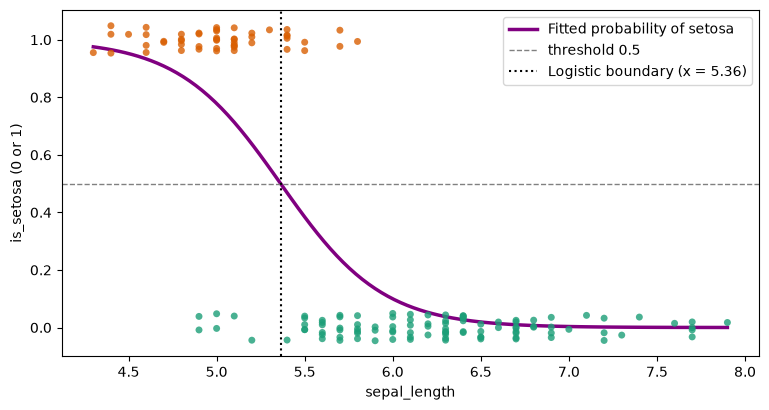

flowers classified wrongly at threshold 0.5: 16


In [23]:
x_values = np.linspace(iris[feature_1d].min(), iris[feature_1d].max(), 100)
y_values = sepal_model.predict_proba(
    pd.DataFrame({feature_1d: x_values})
)[:, 1]

boundary = -sepal_model.intercept_[0] / sepal_model.coef_[0][0]

plt.figure(figsize=(9, 4.5))
sns.stripplot(
    data=iris, x=feature_1d, y="is_setosa", hue="is_setosa", palette="Dark2",
    native_scale=True, orient="h", jitter=0.05, alpha=0.8
)
plt.plot(
    x_values, y_values, c="purple", linewidth=2.5,
    label="Fitted probability of setosa"
)
plt.axhline(0.5, linestyle="--", linewidth=1, color="gray", label="threshold 0.5")
plt.axvline(
    boundary, color="black", linestyle=":",
    label=f"Logistic boundary (x = {boundary:.2f})"
)
plt.xlabel(feature_1d)
plt.ylabel("is_setosa (0 or 1)")
plt.legend()
plt.show()

print(f"flowers classified wrongly at threshold 0.5: {sepal_model_predictions.query("is_setosa != predicted_class").shape[0]}")

Three things to read.

**The sigmoid curve runs downhill** instead of
uphill because the weight is negative. It is the same S, mirrored.

**The curve never reaches 0 or 1.** It approaches them and flattens. A logistic model is never
completely certain, which is useful: it reports how sure it is.

**The curve crosses 0.5 at 5.36 cm.** That length is the model's **decision boundary**: the place
where its answer switches from one class to the other. With one feature the boundary is a single
point. With two features it becomes a line, as the tree and KNN sections show. The model classifies
**16 of the 150** flowers wrongly, and every one of them lies in the range of sepal lengths where
both classes occur. No single cut on sepal length can get every flower right in that range.

Not all 16 mistakes are the same kind of mistake. The next section separates them.

### Four kinds of answer at a threshold

Once a threshold turns each probability into a class, every flower lands in exactly one of four
outcomes. Two are correct and two are mistakes. The names follow one pattern: the second word is what
the model **predicted** (*positive* means setosa, *negative* means other), and the first word says
whether that prediction was **true** or **false**.

- **True positive (TP)** — a setosa, predicted setosa.
- **True negative (TN)** — an other flower, predicted other.
- **False positive (FP)** — an other flower, predicted setosa. The model flagged a flower it should
  not have flagged.
- **False negative (FN)** — a setosa, predicted other. The model missed it.

The share of correct answers is the **accuracy**:

$$\text{accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

where:

- $TP$, $TN$, $FP$, $FN$ — the number of rows in each of the four outcomes above. Each is 0 or more,
  and together they add up to the number of rows.
- accuracy runs from 0 (every answer wrong) to 1 (every answer right).

The cell below draws the predicted probability of setosa for all 150 flowers as two histograms, one
per actual class, with the threshold as a red dashed line. A blue bar left of the line holds true
negatives and right of it false positives; an orange bar left of the line holds false negatives and
right of it true positives. The four counts are written at the top, and the accuracy is printed
underneath:

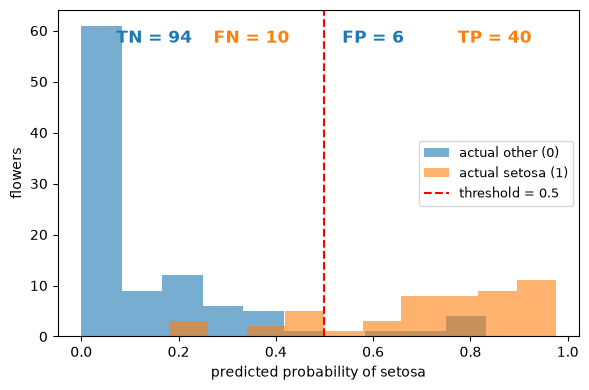

accuracy at threshold 0.5: 0.893


In [24]:
threshold = 0.5
bins = 10
negatives = sepal_model_predictions.query("is_setosa == 0")["P(y=1|feature)"]
positives = sepal_model_predictions.query("is_setosa == 1")["P(y=1|feature)"]

outcomes = {
    "TN": (negatives < threshold).sum(),
    "FN": (positives < threshold).sum(),
    "FP": (negatives >= threshold).sum(),
    "TP": (positives >= threshold).sum(),
}

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(negatives, bins=bins, color="tab:blue", alpha=0.6, label="actual other (0)")
ax.hist(positives, bins=bins, color="tab:orange", alpha=0.6, label="actual setosa (1)")
ax.axvline(threshold, color="red", linestyle="--", label=f"threshold = {threshold}")

label_places = {"TN": (0.15, "tab:blue"), "FN": (0.35, "tab:orange"),
                "FP": (0.60, "tab:blue"), "TP": (0.85, "tab:orange")}
for name, (x_place, colour) in label_places.items():
    ax.text(x_place, 0.9, f"{name} = {outcomes[name]}", transform=ax.get_xaxis_transform(),
            color=colour, fontsize=12, weight="bold", ha="center")

ax.set_xlabel("predicted probability of setosa")
ax.set_ylabel("flowers")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout()
plt.show()

accuracy = (outcomes["TP"] + outcomes["TN"]) / len(sepal_model_predictions)
print(f"accuracy at threshold {threshold}: {accuracy:.3f}")

**134 of the 150 flowers are classified correctly** — 94 true negatives and 40 true positives — an
accuracy of **0.893**. The 16 mistakes from the previous figure split into **10 false negatives**,
setosa flowers with long sepals, and **6 false positives**, other flowers with short sepals.

The line decides which outcome each flower falls in. Move it to the left and some false negatives
become true positives, but some true negatives become false positives. Move it to the right and the
opposite happens. No position removes both kinds of mistake, because the two colours overlap. Part 2
counts these four outcomes in a table and asks where the line should go.

## Decision trees

A **decision tree** predicts by asking a sequence of yes/no questions about the features, and each
answer sends the row down one branch. The questions have a fixed form: *is this feature below this
value?* After enough questions the row arrives somewhere no further question is asked, and whatever
the training rows that landed in the same place did, the tree predicts.

The vocabulary is small and worth fixing before the picture:

- A **node** is one point in the tree.
- The **root node** is the first one, where every row starts.
- A **split** is the question at a node, always of the form *feature <= value*.
- A **leaf** is a node with no question below it. Every row ends at exactly one leaf.
- The **depth** is the number of questions on the longest path from the root to a leaf.

The tree chooses each split by trying candidate cut points and keeping the one that best separates
the classes — the one that leaves each side as **pure** as possible, meaning as close as it can get
to holding only one class. Depth is the main control on how detailed it gets: a deeper tree asks more
questions and carves the data more finely.

Two properties follow from the mechanism, and both come up again later:

- **The tree has no notion of distance or scale.** It only compares a feature against a cut point, so
  multiplying a column by 1,000 changes nothing. It does not need scaling.
- **Every row in a leaf gets the same answer.** So a tree can only produce as many distinct
  probabilities as it has leaves.

> **In `scikit-learn`.** `DecisionTreeClassifier(max_depth=...)` limits the depth. `plot_tree` draws
> the fitted tree. Trees use randomness when features tie, so set `random_state` for a reproducible
> result.

To draw the tree's decision we use two features rather than one, because a cut on two features is a
line on a flat picture. We use both sepal measurements, `sepal_length` and `sepal_width`.

The cell below fits a tree of depth 2 on those two columns and draws the tree itself. Read it from
the top: each box shows the question, how many flowers reached it (`samples`), how many of those are
other and setosa (`value`), and which class wins there:

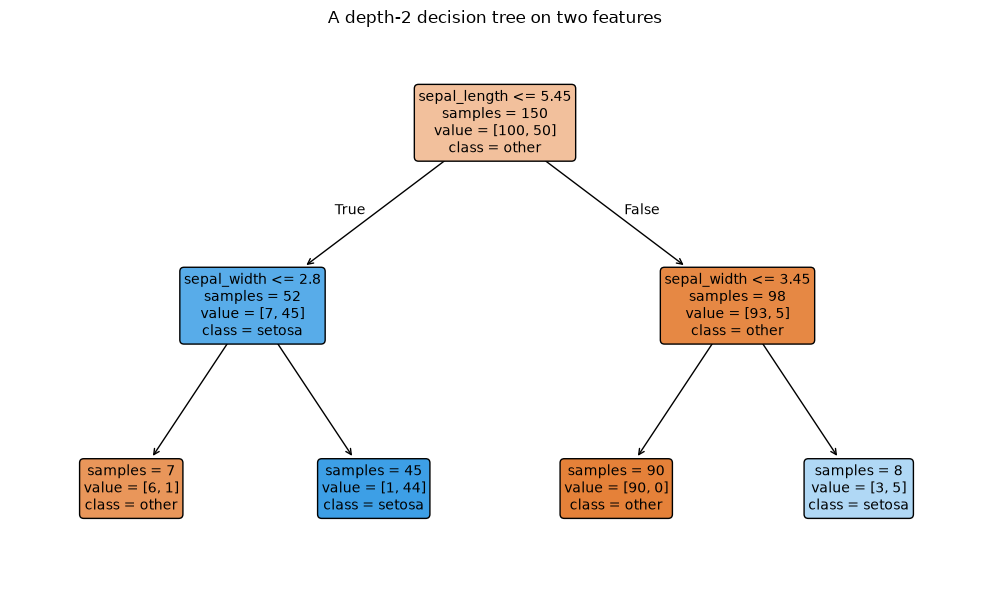

In [27]:
SLICE_COLS = ["sepal_length", "sepal_width"]

slice_tree = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
slice_tree.fit(iris[SLICE_COLS], y_iris)

fig, ax = plt.subplots(figsize=(10, 6))
plot_tree(
    slice_tree,
    feature_names=SLICE_COLS,
    class_names=["other", "setosa"],
    filled=True,
    impurity=False,
    rounded=True,
    fontsize=10,
    ax=ax,
)
ax.set_title("A depth-2 decision tree on two features")
fig.tight_layout()
plt.show()

The root splits on **`sepal_length <= 5.45`**, almost the same cut logistic regression found on its
own (5.36 cm). Below it, both sides split on `sepal_width`. The two large leaves carry the rule:

- short sepals that are not narrow (`sepal_width > 2.8`) — **45 flowers, 44 of them setosa**;
- long sepals that are not wide (`sepal_width <= 3.45`) — **90 flowers, none of them setosa**.

That is a complete rule you can say out loud, extracted from data rather than assumed: *a setosa has
short, wide sepals.* Neither of the other two models in this part can be read like that.

Because both features are quantities, the same tree can be drawn a second way — as regions on the
plane. The cell below defines a helper that colours every point of the sepal length × sepal width
plane by the probability of setosa a model predicts there, and then uses it on the tree:

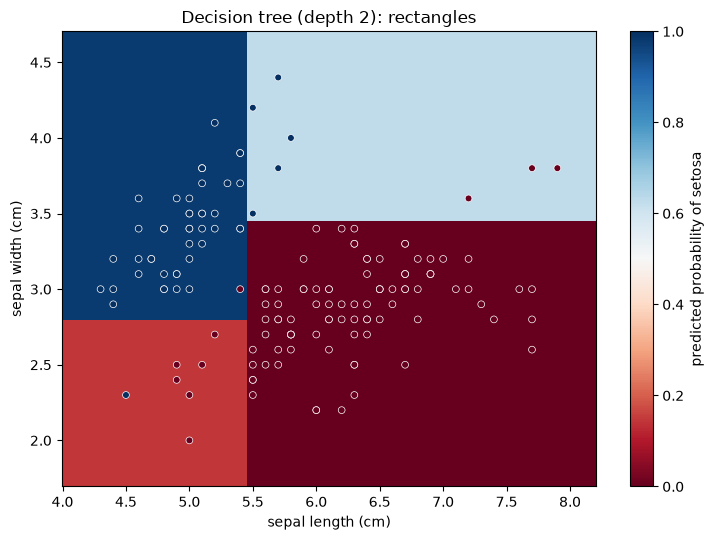

In [26]:
def plot_decision_regions(model, ax, title: str, step: int = 300) -> QuadMesh:
    """Shade the sepal length x sepal width plane by predicted probability of setosa.

    Args:
        model: A fitted classifier accepting the two slice columns.
        ax: The matplotlib axes to draw on.
        title: Title for the panel.
        step: Grid resolution along each axis.

    Returns:
        The shaded mesh, so that a colour bar can be attached to it.
    """
    x_min, x_max = iris["sepal_length"].min() - 0.3, iris["sepal_length"].max() + 0.3
    y_min, y_max = iris["sepal_width"].min() - 0.3, iris["sepal_width"].max() + 0.3
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, step), np.linspace(y_min, y_max, step)
    )
    grid = pd.DataFrame({"sepal_length": xx.ravel(), "sepal_width": yy.ravel()})
    surface = model.predict_proba(grid)[:, 1].reshape(xx.shape)

    mesh = ax.pcolormesh(xx, yy, surface, cmap="RdBu", vmin=0, vmax=1, shading="auto")
    ax.scatter(
        iris["sepal_length"], iris["sepal_width"],
        c=y_iris, cmap="RdBu", edgecolor="white", linewidth=0.5, s=24,
    )
    ax.set_xlabel("sepal length (cm)")
    ax.set_ylabel("sepal width (cm)")
    ax.set_title(title)
    return mesh


fig, ax = plt.subplots(figsize=(7.5, 5.5))
mesh = plot_decision_regions(slice_tree, ax, "Decision tree (depth 2): rectangles")
fig.colorbar(mesh, ax=ax, label="predicted probability of setosa")
fig.tight_layout()
plt.show()

**Every boundary is a straight line parallel to an axis, and every region is a rectangle.** That is
not a drawing choice — it is what the tree *is*. Each split compares one feature against one number,
which can only ever cut straight across one axis. A tree cannot draw a diagonal.

On this plane blue means setosa and red means other, as the colour bar shows. Four leaves give four
rectangles, and so only four possible probabilities. The two large blocks are the rule read off the
tree. The pale blue block at the top right is less sure: it holds 8 flowers, 5 of them setosa.

**Now find the blue point inside the red rectangle at the lower left**, at 4.5 cm by 2.3 cm. It is a
setosa with an unusually narrow sepal, surrounded by flowers of the other species. The tree calls it
"other". Keep it in mind: the next section is about what a model should do with a point like that.

## k-nearest neighbours

**k-nearest neighbours** — KNN — predicts by looking up the training rows most similar to the one it
is asked about. To classify a flower, find the $k$ training flowers closest to it, and let those $k$
vote. The share voting "setosa" is the predicted probability.

Two consequences follow:

- **Almost nothing happens during `fit`.** There are no weights to solve and no questions to choose:
  the training data *is* the model. The work happens at prediction time, when the neighbours must be
  found.
- **"Close" means close in distance**, measured across all feature columns at once. So the **scale**
  of the columns decides the answer. A column measured in thousands would dominate every distance,
  and a column measured in single digits would barely count. Both sepal measurements are in
  centimetres, so scaling changes little here, but on most data it changes everything. Scaling is
  not an improvement to KNN — it is a requirement.

The number $k$ controls how much the model smooths. With $k = 1$ each prediction copies its single
nearest neighbour, so the model follows every individual point. With a large $k$ each prediction
averages over a wide neighbourhood, and the boundary becomes smooth.

> **In `scikit-learn`.** `KNeighborsClassifier(n_neighbors=k)`. Because distances depend on scale,
> it belongs in a pipeline behind a `StandardScaler` essentially always.

The unusual setosa from the tree's picture is the best place to watch $k$ at work. The cell below
finds it — the only setosa with a sepal narrower than 2.5 cm:

In [28]:
unusual_setosa = iris[(iris["is_setosa"] == 1) & (iris["sepal_width"] < 2.5)]
unusual_setosa

,sepal_length,sepal_width,petal_length,petal_width,species,is_setosa
41,4.5,2.3,1.3,0.3,setosa,1


One flower, with measurements that belong to the other species' side of the plane.

The cell below fits KNN on the two sepal measurements at $k = 1$ and at $k = 15$, and draws both with
an arrow on the unusual setosa. Underneath it prints, for each $k$, the accuracy on the flowers the
model was fitted on and the probability of setosa it predicts at the unusual flower's position.
Compare the area around the arrow in the two panels:

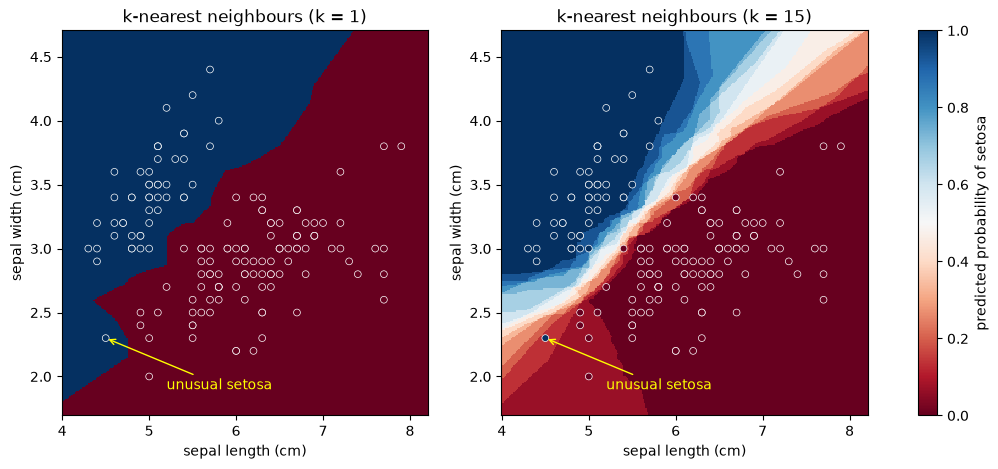

,k,training accuracy,P(setosa) at the unusual flower
0,1,1.000,1.000
1,15,0.993,0.133


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
knn_rows = []
for ax, k in zip(axes, [1, 15]):
    knn_slice = Pipeline(
        [("scale", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=k))]
    ).fit(iris[SLICE_COLS], y_iris)
    mesh = plot_decision_regions(knn_slice, ax, f"k-nearest neighbours (k = {k})")
    ax.annotate(
        "unusual setosa",  color="yellow",
        xy=(unusual_setosa["sepal_length"].iloc[0], unusual_setosa["sepal_width"].iloc[0]),
        xytext=(5.2, 1.9),
        arrowprops={"arrowstyle": "->", "color": "yellow"},
    )
    knn_rows.append(
        {
            "k": k,
            "training accuracy": knn_slice.score(iris[SLICE_COLS], y_iris),
            "P(setosa) at the unusual flower": knn_slice.predict_proba(unusual_setosa[SLICE_COLS])[0, 1],
        }
    )
fig.colorbar(mesh, ax=axes, label="predicted probability of setosa")
plt.show()

pd.DataFrame(knn_rows).round(3)

**At $k = 1$ the model follows every flower.** Look at the arrow: the blue setosa region bulges down
the left edge into the red area, only to take in that single flower. Any new flower measured close to it would be called a setosa, on
the evidence of one flower. The training accuracy is a perfect **1.000**, because every training
flower is its own nearest neighbour. Session 3 showed how little a score on the training data says.

**At $k = 15$ the bulge is gone.** The unusual flower is outvoted by its neighbours, and the
probability of setosa at its position falls from **1.000 to 0.133**. The boundary becomes one smooth
diagonal band between the two groups.

Which picture is right? The unusual flower may be a measurement error, or a real kind of setosa that
deserves its own region. A picture cannot tell you. Only measuring on flowers the model has not seen
can, and Part 2 builds those measurements.

Compare this figure with the tree's. The tree could only cut along the axes, so it drew four
rectangles and had no question to spare for the unusual flower. KNN at $k = 15$ draws the diagonal
that the points suggest. Neither shape is correct in general: which one suits a dataset is something
you measure.

Note also that $k$ is not learned from the data. It is a **hyperparameter**, chosen by you before
fitting — exactly the kind of setting session 3 showed cannot be fitted. Session 5 tunes.

# Part 2 — Measuring a classifier

Part 1 used flowers because flowers can be drawn. Measuring a classifier needs something different:
a problem where the two kinds of mistake cost different amounts, and enough rows to hold a test set
back. So this part moves to customer data, fits the three kinds of model from Part 1 on every
feature, and then measures them.

## The Data: Telco customer churn

We use the **Telco customer churn** dataset, stored with this repository at `data/telco_churn.csv`.

- **7,043 rows and 21 columns.**
- **One row is one customer** of a telecommunications company, described as they were on the day the
  data was collected.
- **The target is `Churn`** — whether that customer had cancelled their service. `Yes` means they
  left, `No` means they stayed. **Churn** is the business word for a customer ending their
  relationship with a company.
- The features describe the account in three groups:
  - **Who the customer is** — `gender`, `SeniorCitizen`, `Partner`, `Dependents`.
  - **What they buy** — `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`,
    `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`.
  - **How the account is billed** — `tenure` (how many months they have been a customer),
    `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`.
- `customerID` is an identifier, not a feature. It is unique to each row, so a model could only
  memorize it. We drop it.

**Why this dataset serves this lesson.** Session 1 opened this course with the question *"reduce
churn": what is that, as a model?* This is that question with data attached. It is also a good
classification teaching set for two specific reasons. The two classes are **unbalanced but not
rare**, which is exactly where accuracy starts to mislead without becoming useless. And retention decisions
have **asymmetric costs** — contacting a customer who was never going to leave wastes an offer,
while missing one who leaves loses the whole account. That asymmetry is what turns the threshold in
this part into a real decision.

The cell below loads the file, drops the identifier column and reports the shape:

In [30]:
churn = pd.read_csv("telco_churn.csv").drop(columns="customerID")

print(f"{churn.shape[0]} rows x {churn.shape[1]} columns")
print(f"missing values reported by pandas: {churn.isna().sum().sum()}")

7043 rows x 20 columns
missing values reported by pandas: 0


7,043 rows and 20 columns once the identifier is gone, and pandas reports no missing values at all.
Hold on to that second number — the next section shows it is wrong.

First, the cell below prints five rows, so that the column list above stops being a list and becomes
customers. Notice how many columns hold text rather than numbers:

In [31]:
churn.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The cell below lists every column with its type and its count of non-empty values:

In [32]:
churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

Most columns are text with a small set of repeated values (`Yes`, `No`, `Month-to-month`,
`Fiber optic`). Only `tenure`, `MonthlyCharges` and `TotalCharges` are quantities.

The cell below counts how many customers left, which sets the number every model in this part
has to beat:

In [33]:
churn["Churn"].value_counts(normalize=True).round(4)

Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64

**About 73.5% stayed and 26.5% left.** Keep the first figure in mind for the rest of the session. A model
that has learned nothing at all, and answers "this customer will stay" for everybody, is right 73.5%
of the time. Any accuracy at or below that number means the model contributed nothing.

A class balance like this one is called **imbalanced** — the two classes are not equally common. At
73.5 / 26.5 the imbalance is mild. Later sections show what happens to each measurement when it is severe.

### Missing values in disguise

`TotalCharges` holds text rather than numbers, which is a warning sign: a column of money should have
loaded as a number. It did not, because some entries are blank, and a single blank forces pandas to
read the whole column as text.

The cell below summarises the column as pandas loaded it: how many values it holds, how many of them
are distinct, and the most frequent one:

In [34]:
churn["TotalCharges"].describe()

count     7043
unique    6531
top       20.2
freq        11
Name: TotalCharges, dtype: object

**A missing value does not always arrive as `NaN`.** It can arrive as a blank string, a zero, a `-1`,
or the word `unknown`. Those pass every automatic check, which is what makes them dangerous.

The cell below converts the column to numbers, turning anything unconvertible into a true missing
value, and then looks at the rows that failed to convert:

In [35]:
churn["TotalCharges"] = pd.to_numeric(churn["TotalCharges"], errors="coerce")
blank_total = churn["TotalCharges"].isna()

print(f"rows that failed to convert: {blank_total.sum()}")
print(f"their tenure values: {sorted(churn.loc[blank_total, 'tenure'].unique())}")
print(f"their churn values : {churn.loc[blank_total, 'Churn'].unique().tolist()}")

rows that failed to convert: 11
their tenure values: [np.int64(0)]
their churn values : ['No']


Eleven rows, and they are not a random eleven. **Every one of them has a `tenure` of 0**, and every
one of them stayed.

That explains the blank completely. `tenure` counts the months a customer has been with the company,
so a tenure of 0 is a customer who signed up and has not yet been billed for a full month. Their
total charges are not unknown — they are **zero**, because nothing has been charged yet.

This changes how we fill the gap. The automatic choice would be the median of the column, around
1,400. That would describe eleven brand-new customers as having already spent a typical amount, which
is false. **Knowing why a value is missing tells you what to put in its place**, and here the honest
replacement is 0.

The cell below fills those eleven values with 0 and converts the target from `Yes`/`No` into 1/0,
because the models need a number. We use 1 for churn, so that "the customer left" is the **positive
class** — the outcome we are trying to detect:

In [36]:
churn["TotalCharges"] = churn["TotalCharges"].fillna(0.0)
churn["Churn"] = (churn["Churn"] == "Yes").astype(int)

print(f"missing values remaining: {churn.isna().sum().sum()}")
print(f"positive class rate: {churn['Churn'].mean():.4f}")

missing values remaining: 0
positive class rate: 0.2654


### Holding back a test set

We split before fitting anything, exactly as session 3 did. One detail matters more in classification
than it did in regression: the split must preserve the class balance.

A random split can, by chance, put more churners on one side than the other. With a 26.5% positive
class that shifts every measurement, and the shift is invisible unless you check for it.
**Stratified** splitting prevents it by drawing separately from each class, so both halves end up
with the same proportion of churners as the full dataset.

> **In `scikit-learn`.** `train_test_split(..., stratify=y)` performs the stratified version. For
> classification, treat it as the default rather than as an option.

The cell below separates the target from the features and splits both, holding out 25% for a final
test. Check that the two churn rates printed underneath match each other, and match the 0.2654 above:

In [37]:
X = churn.drop(columns="Churn")
y = churn["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print(f"training rows: {len(X_train)}   churn rate {y_train.mean():.4f}")
print(f"test rows:     {len(X_test)}   churn rate {y_test.mean():.4f}")

training rows: 5282   churn rate 0.2654
test rows:     1761   churn rate 0.2652


### Preparing the columns

The preparation is the pattern from session 2, in one `ColumnTransformer`: scale the three numeric
columns, one-hot encode the sixteen text columns. Keeping it inside a pipeline means it is refitted
from scratch on the training data alone and never sees the test set, which is the leakage rule from
session 2.

> **In `scikit-learn`.** `drop="if_binary"` removes one of the two columns produced for a yes/no
> feature, since a single column already carries the whole answer. `handle_unknown="ignore"` stops a
> category that appears only in the test set from raising an error.

The cell below builds that recipe, plus a small helper that chains it to any model so that later
cells can name a model in one line. It prints the width of the prepared matrix:

In [38]:
NUMERIC_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_COLS = [column for column in X.columns if column not in NUMERIC_COLS]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), CATEGORICAL_COLS),
    ]
).set_output(transform="pandas")


def make_model(estimator) -> Pipeline:
    """Chain the shared preprocessing recipe to an estimator.

    Args:
        estimator: Any scikit-learn classifier.

    Returns:
        A pipeline that prepares the columns and then applies the estimator.
    """
    return Pipeline([("prep", preprocessor), ("model", estimator)])


X_train_preproc = preprocessor.fit_transform(X_train)
print(f"initial dataset: {len(NUMERIC_COLS)} numeric + {len(CATEGORICAL_COLS)} categorical columns")
print(f"prepared matrix: {X_train_preproc.shape[0]} rows x {X_train_preproc.shape[1]} columns")

initial dataset: 3 numeric + 16 categorical columns
prepared matrix: 5282 rows x 40 columns


Twenty original columns become 40 prepared ones, because each text column expands into one column per
category. That width is still small: every model below fits in about a second.

## Four models on the full feature set

Part 1 drew each kind of model on one or two flower measurements. Now the same three kinds of model
get all forty prepared columns of the churn data.

We add a fourth candidate: a **baseline** that ignores the features entirely and always answers with
the most common class, "stayed". As in session 1, the baseline is not there to compete. It is there
so that every other number has something to be compared against.

The settings are chosen by hand, not tuned: a tree of depth 4, and KNN with $k = 25$. Part 1 showed
what a very small $k$ does; how to choose a setting like this properly is session 5's topic.

The cell below fits all four and reports accuracy on the test set — the share of customers whose
class the model got right. Compare each figure against the baseline before reading anything into it:

In [39]:
models = {
    "Baseline (always 'stayed')": make_model(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_model(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Decision tree (depth 4)": make_model(
        DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
    ),
    "KNN (k=25)": make_model(KNeighborsClassifier(n_neighbors=25)),
}

probabilities = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    probabilities[name] = model.predict_proba(X_test)[:, 1]
    rows.append(
        {"model": name, "test accuracy": accuracy_score(y_test, model.predict(X_test))}
    )

accuracy_table = pd.DataFrame(rows)
accuracy_table.round(4)

,model,test accuracy
0,Baseline (always 'stayed'),0.7348
1,Logistic regression,0.8081
2,Decision tree (depth 4),0.7927
3,KNN (k=25),0.7871


Read the baseline first: **0.7348**. It learned nothing and it is right about three quarters of the
time, because three quarters of customers stay.

Now read the rest. Logistic regression reaches **0.8081**, the tree **0.7927**, KNN **0.7871**. Every
model beats the baseline, so all three learned something — but the best of them improves on "assume
nobody ever leaves" by about **7 percentage points**.

Is that good? The accuracy column cannot tell you, and that is the problem Part 2 opens with.

## Why accuracy is not enough

**Accuracy**, met in Part 1, is the share of rows whose class the model predicted correctly. It is the obvious
measure, and it has one flaw that makes it dangerous on data like ours.

The baseline scored 0.7348 while predicting that **nobody ever leaves**. It never once identified a
churner. As a retention tool it is worthless: it would send zero offers and save zero customers. Yet
it is right about three customers in four, because three customers in four stay.

The more imbalanced the classes, the worse this gets. If churn were 1% instead of 26.5%, the same
useless model would score **99%**, and a model that actually caught half the churners might score
lower. Accuracy collapses two very different mistakes into one number and weights them by how common
each class happens to be.

The fix is to stop asking *how many did it get right* and start asking **which kind of mistake did it
make**. Churn has two, and they cost different amounts:

- The model says "will leave" about somebody who was going to stay. You send a retention offer that
  was not needed, and you lose the cost of the offer.
- The model says "will stay" about somebody who leaves. You do nothing, and you lose the customer.

Those are not equally bad, and no single accuracy figure can tell them apart.

## Probabilities, and how finely each model can answer

Before separating the mistakes, look at what the models actually produce. Each one returned a
probability for every test customer, and the three models differ enormously in **how many distinct
probabilities they can produce at all**.

The cell below counts the distinct values in each model's output:

In [40]:
granularity = pd.DataFrame(
    [
        {"model": name, "distinct probabilities": len(np.unique(values))}
        for name, values in probabilities.items()
    ]
)
granularity

,model,distinct probabilities
0,Baseline (always 'stayed'),1
1,Logistic regression,1758
2,Decision tree (depth 4),14
3,KNN (k=25),25


The numbers come straight from the mechanisms in Part 1.

- **Logistic regression: about 1,758** distinct values, for 1,761 test customers. Almost every
  customer gets their own number, because the weighted sum is different for each of them.
- **Decision tree: 14.** The tree has fourteen leaves, and every customer landing in a leaf gets that
  leaf's answer. Fourteen is all it has.
- **KNN: 25.** Twenty-five neighbours vote, so the only possible answers are $0/25, 1/25, \dots,
  25/25$.
- **Baseline: 1.** It says the same thing about everybody.

The cell below draws the three distributions so the difference is visible rather than counted:

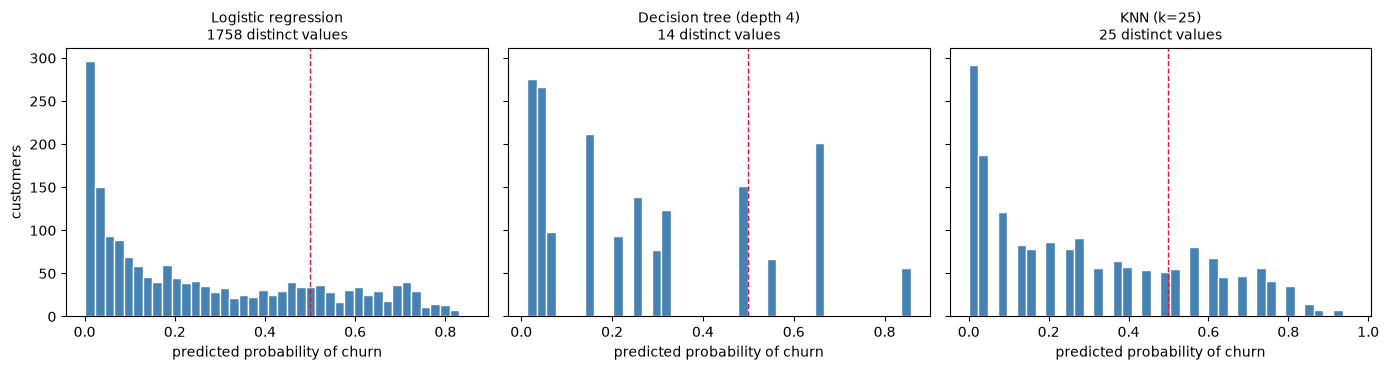

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, name in zip(axes, ["Logistic regression", "Decision tree (depth 4)", "KNN (k=25)"]):
    ax.hist(probabilities[name], bins=40, color="steelblue", edgecolor="white")
    ax.axvline(0.5, color="crimson", linestyle="--", linewidth=1)
    ax.set_title(f"{name}\n{len(np.unique(probabilities[name]))} distinct values", fontsize=10)
    ax.set_xlabel("predicted probability of churn")
axes[0].set_ylabel("customers")
fig.tight_layout()
plt.show()

Logistic regression spreads customers across the whole range. The tree piles them onto fourteen
spikes. KNN sits in between, on its twenty-five allowed values.

This is what the **threshold** — the red line at 0.5 — operates on. Moving that line is how you turn
probabilities into decisions, and a model with fourteen possible answers gives you far fewer places
to put it than one with 1,758. Everything in the rest of this part is built on sliding that line.

## The confusion matrix

To separate the kinds of mistake, count them separately. Part 1 sorted the flowers into four
outcomes, and the same four exist for every problem with two classes. The table holding their counts
is the **confusion matrix**.

With churn as the positive class:

|  | model says **stay** | model says **leave** |
|---|---|---|
| **actually stayed** | true negative (TN) | false positive (FP) |
| **actually left** | false negative (FN) | true positive (TP) |

where:

- **TP** — customers who left and were predicted to leave. Caught.
- **TN** — customers who stayed and were predicted to stay. Correctly left alone.
- **FP** — customers who stayed but were predicted to leave. A wasted retention offer. Also called a
  **false alarm**.
- **FN** — customers who left but were predicted to stay. A customer lost with no attempt to keep
  them. Also called a **miss**.

Accuracy is $(TP + TN) / (TP + TN + FP + FN)$ — all four boxes collapsed into one number. The matrix
keeps them apart.

> **In `scikit-learn`.** `confusion_matrix(y_true, y_pred)` returns the four counts in the order
> `[[TN, FP], [FN, TP]]`. `ConfusionMatrixDisplay` draws it.

The cell below draws the matrix for logistic regression at the usual 0.5 threshold:

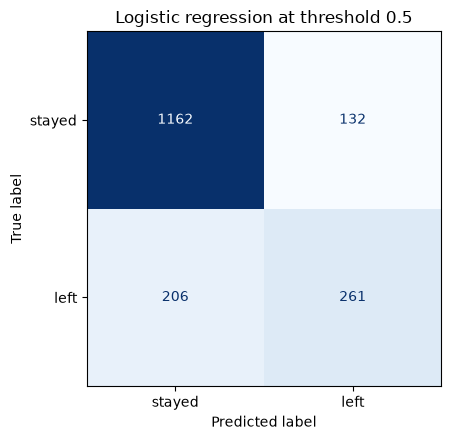

true negatives   1162   false positives   132
false negatives   206   true positives    261


In [42]:
logistic_probabilities = probabilities["Logistic regression"]
logistic_predictions = (logistic_probabilities >= 0.5).astype(int)

matrix = confusion_matrix(y_test, logistic_predictions)
true_negative, false_positive, false_negative, true_positive = matrix.ravel()

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(matrix, display_labels=["stayed", "left"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Logistic regression at threshold 0.5")
fig.tight_layout()
plt.show()

print(f"true negatives  {true_negative:5d}   false positives {false_positive:5d}")
print(f"false negatives {false_negative:5d}   true positives  {true_positive:5d}")

The counts are **TN 1162, FP 132, FN 206, TP 261**.

Read the bottom row, because it is the one the business cares about. There were $206 + 261 = 467$
customers who actually left. The model caught **261** of them and missed **206** — it found a little
over half. The accuracy of 0.8081 did not say that anywhere.

## Precision, recall and F1

The matrix has four numbers, which is too many to rank models with. Two ratios summarise it, and they
answer two different questions.

**Precision** answers: *when the model says "will leave", how often is it right?*

$$\text{precision} = \frac{TP}{TP + FP}$$

where:

- $TP$ — true positives, churners correctly identified.
- $FP$ — false positives, stayers wrongly flagged.
- precision runs from 0 to 1. It is the share of the flagged customers who really were leaving, so it
  measures **wasted effort**: low precision means offers sent to people who were never going to go.

**Recall** answers: *of the customers who actually left, how many did the model find?*

$$\text{recall} = \frac{TP}{TP + FN}$$

where:

- $FN$ — false negatives, churners the model missed.
- recall runs from 0 to 1. It is the share of real churners that were caught, so it measures
  **missed opportunity**: low recall means customers walked out with no attempt to keep them.

The two pull against each other. Flag more customers and you catch more churners (recall rises) but
more of your flags are wrong (precision falls). Flag almost nobody and the few you flag are probably
right (precision rises) while most churners escape (recall falls). Either one alone can be made
perfect by a model that is useless, so they are always read together.

**F1** combines them into one number:

$$F_1 = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

where:

- $F_1$ — runs from 0 to 1, higher is better.
- It is the **harmonic mean** of the two, not the ordinary average. The harmonic mean is pulled
  towards the smaller of the two values, so $F_1$ stays low unless *both* are decent. An ordinary
  average would let precision 1.0 and recall 0.0 score 0.5; $F_1$ scores it 0.

The cell below computes all three for every model, next to accuracy:

In [ ]:
rows = []
for name, values in probabilities.items():
    predictions = (values >= 0.5).astype(int)
    rows.append(
        {
            "model": name,
            "accuracy": accuracy_score(y_test, predictions),
            "precision": precision_score(y_test, predictions, zero_division=0),
            "recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions, zero_division=0),
        }
    )

metrics_table = pd.DataFrame(rows)
metrics_table.round(4)

The baseline's row is the one to read first. Its accuracy is **0.7348** — the highest-looking number
in that column after logistic regression — and its precision, recall and F1 are all **0**. It never
predicts churn, so it has no true positives at all. One column called it respectable; three columns
show it is worthless.

Among the real models, **no single one wins every column**, and that is the more interesting result.

- **Logistic regression** has the best F1 (**0.607**) and the best precision (**0.664**). When it
  flags a customer it is right about two times in three.
- **KNN finds more churners than logistic regression does** — recall **0.591** against **0.559** —
  but pays for it in precision, **0.600** against 0.664. It casts a slightly wider net.
- **The decision tree is the most cautious.** Its precision is almost logistic regression's
  (**0.657**) but its recall is far the worst (**0.456**): it flags fewer customers and lets more
  churners through.

So the three models sit at three different points on the same trade between wasted effort and missed
opportunity. Ranking them needs you to say which of those two you care about more — and that is not a
property of the models. It is a property of the decision you are making with them.

Notice also that all three were measured at the same fixed threshold of 0.5. The next section shows
that this choice, not the choice of model, is the larger lever.

## The threshold is a decision

Everything above used 0.5. Nothing requires that. The threshold is the line between "flag this
customer" and "leave them alone", and moving it trades precision against recall directly.

The business question decides where to put it. For retention:

- **A false positive costs one retention offer** — a discount, a call, some small amount.
- **A false negative costs a whole customer** — every month they would have paid from now on.

When a miss costs much more than a false alarm, you want **high recall**, and you accept the wasted
offers that come with it. You lower the threshold.

The cell below applies six thresholds to the same logistic regression probabilities — the model is
not refitted, only the line moves — and reports what each one does:

In [ ]:
rows = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    predictions = (logistic_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    rows.append(
        {
            "threshold": threshold,
            "flagged": int(predictions.sum()),
            "caught (TP)": tp,
            "false alarms (FP)": fp,
            "missed (FN)": fn,
            "precision": precision_score(y_test, predictions, zero_division=0),
            "recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions, zero_division=0),
        }
    )

threshold_table = pd.DataFrame(rows)
threshold_table.round(4)

Follow one column at a time.

At **0.20** the model flags 840 customers, catches **401 of the 467** churners (recall 0.859) and
raises 439 false alarms (precision 0.477). At **0.70** it flags only 125, catches **94** (recall
0.201) and is right three times in four (precision 0.752).

**Same model, same probabilities, same test set.** Recall moved from 0.86 to 0.20 because a number
was changed. If you report "the model has 56% recall" without saying which threshold you used, you
have reported almost nothing.

Note also that **F1 peaks at 0.40, not 0.50**, at 0.632. The default threshold was not even the best
compromise by F1's own definition, let alone by the cost of the business decision.

The cell below draws the same information as curves, so the trade is visible as a shape:

In [ ]:
sweep = np.linspace(0.05, 0.95, 91)
precisions, recalls, f_ones = [], [], []
for threshold in sweep:
    predictions = (logistic_probabilities >= threshold).astype(int)
    precisions.append(precision_score(y_test, predictions, zero_division=0))
    recalls.append(recall_score(y_test, predictions, zero_division=0))
    f_ones.append(f1_score(y_test, predictions, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep, precisions, label="precision", linewidth=2)
ax.plot(sweep, recalls, label="recall", linewidth=2)
ax.plot(sweep, f_ones, label="F1", linewidth=2, linestyle="--", color="grey")
ax.axvline(0.5, color="black", linewidth=1, linestyle=":")
ax.text(0.51, 0.05, "default 0.5", fontsize=9)
ax.set_xlabel("threshold")
ax.set_ylabel("score")
ax.set_title("Moving the threshold trades precision against recall")
ax.legend()
fig.tight_layout()
plt.show()

The two solid lines cross. To the left of the crossing the model is a wide net: it catches most
churners and wastes many offers. To the right it is a narrow net: few offers, mostly correct, most
churners missed.

**There is no setting that is best in general.** There is only the setting that matches what the two
mistakes cost your business, which is a number the data does not contain and somebody has to supply.

## ROC curve and AUC

If the threshold is a choice, then any single-threshold metric describes one arbitrary point. It is
often more useful to ask how good the model's **ranking** is — whether it gives churners higher
probabilities than stayers — independently of where the line ends up.

The **ROC curve** does that. It sweeps the threshold from 1 down to 0 and plots two quantities
against each other at every setting:

$$\text{TPR} = \frac{TP}{TP + FN} \qquad \text{FPR} = \frac{FP}{FP + TN}$$

where:

- **TPR** — the **true positive rate**, identical to recall. The share of real churners caught. Runs
  from 0 to 1.
- **FPR** — the **false positive rate**. The share of stayers wrongly flagged. Runs from 0 to 1.

Each threshold gives one point. Lowering the threshold raises both rates, so the curve travels from
the bottom-left corner (flag nobody) to the top-right (flag everybody). A model that ranks well
climbs steeply first, gaining true positives before it starts collecting false ones, and so bows
towards the top-left.

**AUC** is the area under that curve:

- $\text{AUC} = 1$ — perfect ranking: every churner scored above every stayer.
- $\text{AUC} = 0.5$ — the diagonal, the same ranking as random guessing.
- AUC has a direct reading: it is the probability that a randomly chosen churner is given a higher
  score than a randomly chosen stayer.

The cell below draws all three real models on one pair of axes. Watch the shape of the KNN curve in
particular:

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name in ["Logistic regression", "Decision tree (depth 4)", "KNN (k=25)"]:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities[name])
    area = roc_auc_score(y_test, probabilities[name])
    ax.plot(false_positive_rate, true_positive_rate, linewidth=2, label=f"{name} (AUC {area:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1, label="random (AUC 0.500)")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate (recall)")
ax.set_title("ROC curves")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

Logistic regression reaches **AUC 0.847**, the tree **0.832**, KNN **0.833**.

**Look at how the three curves are built.** Logistic regression's wanders in many small steps, while
the tree's is made of a few long straight runs — clearest between false positive rates of 0.25 and
0.4, where it travels in one line while the blue curve keeps bending. That is the granularity from
the start of this part, drawn: the tree has only fourteen distinct probabilities, so there are only
fourteen places a threshold can go, and between them nothing changes. The model cannot be adjusted
more finely than that, however much you would like to.

Note too that the tree and KNN are separated by **0.0003** of AUC. On this evidence they are the same
model. Session 3's lesson applies unchanged — a difference that small is not a finding, and the
honest report is that these two could not be told apart.

## Precision-recall curve

ROC has a blind spot, and it is worth seeing before trusting an AUC.

Look again at the false positive rate: $FP / (FP + TN)$. Its denominator is the number of customers
who **stayed**. In our data that is 1,294 people, so a few hundred false alarms barely move it. When
the negative class is large, FPR is divided by a large number and stays small no matter what.

The **precision-recall curve** replaces FPR with precision, whose denominator is $TP + FP$ — the
number of customers **flagged**. That has nothing to do with how many negatives exist, so the curve
keeps reacting to false alarms even when negatives vastly outnumber positives.

The summary number is **average precision**, the area under this curve. Its floor is not 0.5: a
random model scores the **share of positives in the data**, which is 0.265 here.

The cell below draws the precision-recall curves for the same three models:

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name in ["Logistic regression", "Decision tree (depth 4)", "KNN (k=25)"]:
    precision_values, recall_values, _ = precision_recall_curve(y_test, probabilities[name])
    average = average_precision_score(y_test, probabilities[name])
    ax.plot(recall_values, precision_values, linewidth=2, label=f"{name} (AP {average:.3f})")

ax.axhline(y_test.mean(), linestyle="--", color="grey", linewidth=1,
           label=f"random (AP {y_test.mean():.3f})")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision-recall curves")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

Logistic regression scores **AP 0.639** against a random floor of **0.265**. The ordering of the
models is the same as ROC gave, which is what you expect when the classes are only mildly imbalanced.

The curve falls to the right: pushing recall towards 1 costs precision steeply. At recall 0.8 the
model is right about half the time it flags somebody.

## When the positive class is rare

Our churn rate is 26.5%, which is imbalanced but comfortable. Many real classification problems are
far more extreme — fraud at 1 in 500, a rare disease at 1 in 10,000. The claim to test is that ROC
becomes misleading there while precision-recall does not.

We can test it on this data without changing models. Keep the **same fitted logistic regression** and
the **same predicted probabilities**, and only change the makeup of the test set: keep every customer
who stayed, and randomly drop most of those who left. Nothing about the model changes — only how rare
the positive class is.

Because the result depends on which churners are dropped, the cell below repeats the draw 20 times
with a fixed seed and averages, reporting the spread as well:

In [ ]:
def thin_positives(fraction: float, draws: int = 20) -> dict[str, float]:
    """Measure ROC AUC and average precision after thinning the positive class.

    Args:
        fraction: Share of positive rows to keep.
        draws: Number of random subsets to average over.

    Returns:
        Mean prevalence, mean ROC AUC and mean average precision, with spreads.
    """
    generator = np.random.default_rng(RANDOM_STATE)
    outcomes = y_test.to_numpy()
    positive_index = np.flatnonzero(outcomes == 1)
    negative_index = np.flatnonzero(outcomes == 0)

    prevalences, areas, averages = [], [], []
    for _ in range(draws):
        kept = generator.choice(positive_index, int(len(positive_index) * fraction), replace=False)
        index = np.concatenate([negative_index, kept])
        subset_y, subset_p = outcomes[index], logistic_probabilities[index]
        prevalences.append(subset_y.mean())
        areas.append(roc_auc_score(subset_y, subset_p))
        averages.append(average_precision_score(subset_y, subset_p))

    return {
        "prevalence": np.mean(prevalences),
        "ROC AUC": np.mean(areas),
        "ROC AUC sd": np.std(areas),
        "avg precision": np.mean(averages),
        "avg precision sd": np.std(averages),
    }


rarity_table = pd.DataFrame(
    [
        {"positives kept": "all", **thin_positives(1.0)},
        {"positives kept": "15%", **thin_positives(0.15)},
    ]
)
rarity_table.round(4)

This is the result the section exists for.

| | prevalence | ROC AUC | average precision |
|---|---|---|---|
| all positives | 26.5% | 0.8467 | **0.6387** |
| 15% of positives | 5.1% | **0.8454** | **0.2409** |

**ROC AUC did not move.** It went from 0.8467 to 0.8454 — a change of 0.0013, which is smaller than
its own spread across the twenty draws (0.011). **Average precision collapsed by 62%**, from 0.639 to
0.241.

The model is identical. Its ranking is identical. Only the base rate changed — and one metric
reported no change at all while the other reported a disaster.

Both are telling the truth about different things. ROC AUC measures **ranking quality**, which really
did not change. Average precision measures **how much of your flagged list is worth acting on**, and
that genuinely collapsed: when churners are rare, any list you flag is mostly stayers, no matter how
well the model ranks.

**The rule that follows.** When the positive class is rare and you care about the work created by
false alarms, read the precision-recall curve. A ROC AUC of 0.95 on a fraud problem can sit
comfortably next to a flagged list that is 98% false alarms, and the ROC curve will never tell you.

## More than two classes

Everything so far assumed two classes. Many problems have more — which of five plans a customer will
choose, which of three warehouses to route an order to.

The ideas carry over with one change: every metric is computed **per class**, and then combined. This
is a short section on a topic we should not leave behind, not a second main thread, so we return to
the iris flowers from Part 1 — this time with all **three species** as classes, and all four
measurements as features.

The cell below holds back 30% of the flowers as a stratified test set, fits a tree of depth 2 on the
rest, and prints the confusion matrix and a report with one row per class:

In [ ]:
X_species = iris[MEASUREMENT_COLS]
y_species = iris["species"]
X_species_train, X_species_test, y_species_train, y_species_test = train_test_split(
    X_species, y_species, test_size=0.3, stratify=y_species, random_state=RANDOM_STATE
)

species_model = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
species_model.fit(X_species_train, y_species_train)
species_predictions = species_model.predict(X_species_test)

print(confusion_matrix(y_species_test, species_predictions))
print()
print(classification_report(y_species_test, species_predictions, digits=3))

The confusion matrix is now **3 × 3** rather than 2 × 2. Its rows are the true species and its columns
the predicted ones, both in the order setosa, versicolor, virginica. The diagonal holds the correct
predictions, and every other cell is one specific confusion: three versicolor flowers were called
virginica, and two virginica flowers were called versicolor.

The per-class rows say something the single accuracy of 0.889 hides. **Setosa is perfect** —
precision 1.000, recall 1.000, never confused with anything. That is Part 1's picture again: setosa
stands apart from the other two species. The errors are entirely between versicolor and virginica,
which this shallow tree cannot fully separate. That is a specific, actionable finding: work on
telling those two apart, and ignore the third.

The last two lines show two ways of combining the per-class scores into one number:

- **macro average** — the plain mean of the per-class scores. Every class counts equally, however
  rare it is.
- **weighted average** — the mean weighted by how many rows each class has. Common classes dominate.

A third, **micro average**, pools all the counts before computing the metric; for single-label
problems like this it works out exactly equal to accuracy.

Here the macro and weighted rows are identical, because the classes are exactly balanced: 15 test
flowers of each species, so weighting by size changes nothing. **They diverge when the classes are
not balanced** — and then the choice matters: macro is the honest measure when a rare class is the
one you care about, since weighting by size would let a large easy class hide failure on a small
important one.

# Wrap-up

## What this session established

- **A classifier's real output is a probability.** The class is produced afterwards, by comparing
  that probability against a threshold.
- **Three models reach that probability three different ways.** Logistic regression squashes a
  weighted sum through the sigmoid. A decision tree asks yes/no questions and answers with its leaf.
  KNN takes a vote among the closest training rows. Their decision boundaries have different shapes —
  rectangles for the tree, smooth curves for KNN — and neither shape is right in general.
- **The number of neighbours decides what KNN does with an unusual point.** At $k = 1$ one unusual
  setosa got a region of its own and the training accuracy was a perfect 1.000; at $k = 15$ it was
  outvoted.
- **How a model works decides how finely it can answer.** On the same test set logistic regression
  produced 1,758 distinct probabilities, KNN 25 and the tree 14. That limit is visible as corners in
  the model's ROC curve.
- **Accuracy hides which mistake was made.** A baseline predicting "nobody leaves" scored 0.735 with
  precision, recall and F1 all exactly 0.
- **The confusion matrix separates the four outcomes**, and precision and recall summarise it from
  two directions: wasted effort and missed opportunity. F1 combines them with a harmonic mean, so
  both must be decent.
- **The threshold is a business decision, not a constant.** Moving it from 0.7 to 0.2 took the same
  model from recall 0.201 to recall 0.859. Quoting a recall without the threshold says almost
  nothing. F1 peaked at 0.40, not at the default 0.50.
- **ROC measures ranking; precision-recall measures the worth of your flagged list.** With the model
  and its predictions held fixed and only the base rate changed from 26.5% to 5.1%, ROC AUC moved by
  0.0013 while average precision fell from 0.639 to 0.241. Choose the curve that matches your
  question.
- **With more than two classes, read the per-class rows first.** On the iris flowers, setosa was
  perfect and every error was a confusion between versicolor and virginica — which the headline
  accuracy of 0.889 concealed.

## What this session did not do

**We never tuned anything.** The tree's depth of 4 and KNN's $k$ of 25 were chosen by hand, and the
notebook said so when they were chosen. Session 3 showed why a hyperparameter cannot be fitted;
**session 5** takes up how to search for one properly, and the metrics built here are what that
search will optimize.

**We compared models on a single split.** Every number in Part 2 comes from one test set, so every
one of them carries the split lottery that session 3 measured. The honest version cross-validates,
and the tree-versus-KNN gap of 0.0003 AUC is exactly the kind of difference that would disappear
under it.

**We never asked whether one model is enough.** Three candidates were fitted separately and compared.
**Session 6** asks what happens when you stop choosing between them and combine them instead — and
the decision tree from Part 1 is the building block it starts from.